# Mini-projet IA hybride – Sujet 4 : lésions de la peau sous contraintes logiques

**Groupe 4** : Lina Khadly, Alexis Dechenais · ISIS Castres, 5e année DSIA

**Question clinique.** Classer des images de lésions cutanées en 7 types, avec des sorties **cohérentes** avec la hiérarchie
médicale (bénin / malin), une **incertitude exploitable**, et **peu d'images étiquetées**.

**Idée hybride.** On ajoute au réseau une connaissance symbolique très simple, la hiérarchie :

$$\text{type}(x) = k \;\Rightarrow\; \text{groupe}(x) = g(k)$$

où $g$ envoie chaque type vers « bénin » ou « malin / pré-malin ». C'est le même principe que le TP MNIST (séance 3) :
là-bas la règle `somme = a + b` reliait une étiquette globale (la somme) aux classes fines (les chiffres) ;
ici la règle relie l'étiquette globale (le groupe) aux types fins.

**Plan du notebook**

| Étape | Contenu |
|---|---|
| 0 | Préparation, reproductibilité |
| 1 | Données, classes, hiérarchie (justifiée et sourcée) |
| 2 | Métriques : performance, cohérence, calibration |
| 3 | Modèle et pertes : référence, multi-tâche, pertes logiques |
| 4 | Expérience principale : 100 % et 10 % des étiquettes fines, 3 graines |
| 5 | Ablations : on retire chaque brique |
| 6 | Courbe d'apprentissage : de 2 % à 100 % des étiquettes |
| 7 | Calibration : diagrammes de fiabilité, température |
| 8 | Cas difficiles : classes rares, perturbations, hors distribution |
| 9 | Analyse d'erreurs brique par brique |
| 10 | Explication d'une décision et règle d'escalade (prédiction conforme) |
| 11 | Coût et synthèse sur la grille d'évaluation |

## 0. Préparation

On fixe les graines aléatoires pour que tout soit réexécutable. Tout tourne sur CPU (environ une minute par modèle, 30 à 45 min pour le notebook complet) ;
un GPU est utilisé automatiquement s'il est disponible.

In [1]:
import os, time, random, warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, balanced_accuracy_score, roc_auc_score

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))

def fixer_graine(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

fixer_graine(0)
print("PyTorch", torch.__version__, "| appareil :", DEVICE)

# Mode rapide (pour tester que tout s'exécute) : moins de pas d'entraînement et une seule graine.
RAPIDE = os.environ.get("RAPIDE", "0") == "1"
PAS = 150 if RAPIDE else 1200         # nombre de pas d'optimisation par modèle (identique pour tous les modèles)
GRAINES = [0] if RAPIDE else [0, 1, 2]
LOT = 128
print("Mode rapide" if RAPIDE else "Mode complet", "| pas :", PAS, "| graines :", GRAINES)

PyTorch 2.14.1+cpu | appareil : cpu
Mode complet | pas : 1200 | graines : [0, 1, 2]


## 1. Données

### 1.1 Chargement

DermaMNIST (collection MedMNIST v2, Yang et al., 2023) est une version 28×28 de **HAM10000** (Tschandl et al., 2018) :
10 015 images dermatoscopiques, déjà découpées en entraînement / validation / test.
Le fichier `dermamnist.npz` se télécharge sur Zenodo (voir le README) et se place dans `data/`.
Si le paquet `medmnist` est installé et que le réseau le permet, on peut aussi le télécharger automatiquement.

In [2]:
CHEMIN = "data/dermamnist.npz"
if not os.path.exists(CHEMIN):
    from medmnist import DermaMNIST
    os.makedirs("data", exist_ok=True)
    DermaMNIST(split="train", download=True, root="data")   # crée data/dermamnist.npz

brut = np.load(CHEMIN)
def tenseurs(split):
    X = torch.tensor(brut[f"{split}_images"]).permute(0, 3, 1, 2).float() / 255   # (N, 3, 28, 28)
    y = torch.tensor(brut[f"{split}_labels"]).view(-1).long()
    return X, y

Xtr, ytr = tenseurs("train"); Xva, yva = tenseurs("val"); Xte, yte = tenseurs("test")
MOY = Xtr.mean((0, 2, 3), keepdim=True); ECT = Xtr.std((0, 2, 3), keepdim=True)
normaliser = lambda X: (X - MOY) / ECT       # statistiques calculées sur l'entraînement seulement (pas de fuite)
Xtr_n, Xva_n, Xte_n = normaliser(Xtr), normaliser(Xva), normaliser(Xte)
print("entraînement", tuple(Xtr.shape), "| validation", tuple(Xva.shape), "| test", tuple(Xte.shape))

entraînement (7007, 3, 28, 28) | validation (1003, 3, 28, 28) | test (2005, 3, 28, 28)


### 1.2 Les 7 classes et leur ordre

Le sujet demande de **vérifier l'ordre des classes** dans `info["label"]` : on ne le suppose pas, on le lit dans
les métadonnées de MedMNIST et on vérifie par les noms.

In [3]:
try:
    from medmnist import INFO
    LABELS = INFO["dermamnist"]["label"]
except ImportError:   # copie des métadonnées officielles de MedMNIST v2, au cas où le paquet manque
    LABELS = {"0": "actinic keratoses and intraepithelial carcinoma", "1": "basal cell carcinoma",
              "2": "benign keratosis-like lesions", "3": "dermatofibroma", "4": "melanoma",
              "5": "melanocytic nevi", "6": "vascular lesions"}
NOMS = [LABELS[str(k)] for k in range(7)]
ABREV = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]   # abréviations de HAM10000
NOMS_FR = ["kératose actinique / carcinome intraépithélial", "carcinome basocellulaire", "kératose bénigne",
           "dermatofibrome", "mélanome", "nævus", "lésion vasculaire"]

# vérification de l'ordre par mots-clés
for k, mot in enumerate(["actinic", "basal", "benign", "dermatofibroma", "melanoma", "nevi", "vascular"]):
    assert mot in NOMS[k], f"ordre inattendu pour la classe {k} : {NOMS[k]}"
MEL = 4
for k in range(7):
    print(k, ABREV[k].ljust(6), NOMS[k])

0 akiec  actinic keratoses and intraepithelial carcinoma
1 bcc    basal cell carcinoma
2 bkl    benign keratosis-like lesions
3 df     dermatofibroma
4 mel    melanoma
5 nv     melanocytic nevi
6 vasc   vascular lesions


### 1.3 La hiérarchie bénin / malin (connaissance symbolique)

| Type | Groupe | Justification |
|---|---|---|
| akiec : kératoses actiniques et carcinome intraépithélial (maladie de Bowen) | **malin / pré-malin** | Lésions qui peuvent évoluer en carcinome épidermoïde invasif (Tschandl et al., 2018) ; risque faible pour la kératose actinique, moins d'une sur 1 000 par an (de Berker et al., 2017). La maladie de Bowen est un carcinome *in situ*. |
| bcc : carcinome basocellulaire | **malin** | Cancer cutané le plus fréquent (Tschandl et al., 2018). |
| mel : mélanome | **malin** | Tumeur maligne des mélanocytes (Tschandl et al., 2018). |
| bkl : kératoses bénignes (kératose séborrhéique, lentigo solaire, kératose lichénoïde) | bénin | Lésions bénignes (Tschandl et al., 2018). |
| df : dermatofibrome | bénin | Prolifération fibreuse bénigne (Tschandl et al., 2018). |
| nv : nævus mélanocytaire | bénin | Tumeur bénigne des mélanocytes (Tschandl et al., 2018). |
| vasc : lésions vasculaires (angiomes, angiokératomes, granulomes pyogéniques) | bénin | Non qualifiées explicitement dans Tschandl et al. (2018) ; angiomes et granulomes pyogéniques sont des lésions bénignes : notre choix. |

Ce regroupement s'appuie sur les descriptions de HAM10000 (bcc et mel malins, akiec pouvant évoluer en carcinome,
nv, bkl et df bénins) ; le classement de vasc est le nôtre. Choix discutable : on range akiec avec les malins
parce que, pour un dépistage, une lésion pré-maligne doit être vue par un dermatologue au même titre qu'un cancer.

On code la hiérarchie par un vecteur `GROUPE` (type → groupe) et une matrice $H$ de taille 7×2 avec
$H[k, g] = 1$ si le type $k$ appartient au groupe $g$ (équivalent du masque $M$ du TP MNIST).

classe  groupe              train   val  test  % train
akiec   malin/pré-malin       228    33    66     3.3%
bcc     malin/pré-malin       359    52   103     5.1%
bkl     bénin                 769   110   220    11.0%
df      bénin                  80    12    23     1.1%
mel     malin/pré-malin       779   111   223    11.1%
nv      bénin                4693   671  1341    67.0%
vasc    bénin                  99    14    29     1.4%
Part de malins : train 19.5% | test 19.6%


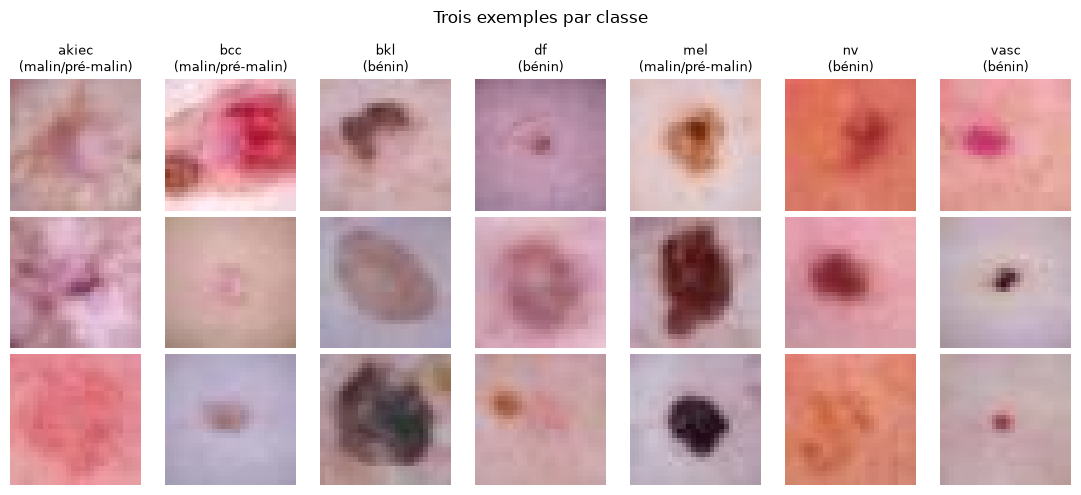

In [4]:
GROUPE = torch.tensor([1, 1, 0, 0, 1, 0, 0])        # 1 = malin / pré-malin, 0 = bénin
NOMS_GROUPE = ["bénin", "malin/pré-malin"]
H = F.one_hot(GROUPE, 2).float()                     # (7, 2)
gtr, gva, gte = GROUPE[ytr], GROUPE[yva], GROUPE[yte]

def tableau_effectifs():
    print(f"{'classe':8s}{'groupe':18s}{'train':>7s}{'val':>6s}{'test':>6s}{'% train':>9s}")
    for k in range(7):
        n = [(y == k).sum().item() for y in (ytr, yva, yte)]
        print(f"{ABREV[k]:8s}{NOMS_GROUPE[GROUPE[k]]:18s}{n[0]:7d}{n[1]:6d}{n[2]:6d}{100*n[0]/len(ytr):8.1f}%")
    print(f"Part de malins : train {gtr.float().mean():.1%} | test {gte.float().mean():.1%}")
tableau_effectifs()

fig, axes = plt.subplots(3, 7, figsize=(11, 5))
for k in range(7):
    idx = (ytr == k).nonzero().view(-1)[:3]
    for r in range(3):
        axes[r, k].imshow(Xtr[idx[r]].permute(1, 2, 0)); axes[r, k].axis("off")
    axes[0, k].set_title(f"{ABREV[k]}\n({NOMS_GROUPE[GROUPE[k]]})", fontsize=9)
plt.suptitle("Trois exemples par classe"); plt.tight_layout(); plt.show()

**À retenir.** Les classes sont très déséquilibrées : les nævus représentent environ deux tiers des images.
Un modèle qui répond toujours « nævus » aurait déjà ~67 % de précision globale. On regardera donc surtout la
**précision équilibrée** (moyenne des rappels par classe), le **F1 macro** et le **rappel du mélanome**.

### 1.4 Régime peu supervisé : 10 % des étiquettes fines

On tire 10 % des images d'entraînement dont on garde le type ; pour les 90 % restantes on ne connaît que le groupe
(bénin / malin), comme le demande le sujet. Le tirage est **stratifié** par classe (sinon une classe rare comme
le dermatofibrome pourrait n'avoir presque aucun exemple) et **fixé** une fois pour toutes : tous les modèles
voient le même sous-ensemble.

In [5]:
def masque_etiquettes(fraction, graine=123):
    """Masque booléen des images d'entraînement dont on garde l'étiquette fine (tirage stratifié)."""
    if fraction >= 1: return torch.ones(len(ytr), dtype=torch.bool)
    g = torch.Generator().manual_seed(graine); m = torch.zeros(len(ytr), dtype=torch.bool)
    for k in range(7):
        idx = (ytr == k).nonzero().view(-1)
        n = max(1, round(fraction * len(idx)))
        m[idx[torch.randperm(len(idx), generator=g)[:n]]] = True
    return m

M10 = masque_etiquettes(0.10)
print("Étiquettes fines gardées à 10 % :", int(M10.sum()), "images ;",
      {ABREV[k]: int((ytr[M10] == k).sum()) for k in range(7)})

Étiquettes fines gardées à 10 % : 701 images ; {'akiec': 23, 'bcc': 36, 'bkl': 77, 'df': 8, 'mel': 78, 'nv': 469, 'vasc': 10}


## 2. Métriques

Le protocole commun demande au moins quatre dimensions de la grille. On mesure :

* **Performance** : précision globale, précision équilibrée, F1 macro, **rappel du mélanome**, rappel et AUC du groupe malin.
* **Cohérence** : taux d'images où la tête « type » et la tête « groupe » se contredisent
  (par exemple type = mélanome mais groupe = bénin).
* **Calibration** : ECE (*expected calibration error*) : on range les prédictions par niveau de confiance
  et on compare la confiance moyenne à la précision réelle dans chaque tranche (Guo et al., 2017).
* **Robustesse** et **coût** : parties 8 et 11 ; **explicabilité** : partie 10.

In [6]:
def ece(confiance, correct, n_tranches=15):
    """Expected Calibration Error : moyenne pondérée de |précision - confiance| par tranche de confiance."""
    confiance, correct = np.asarray(confiance), np.asarray(correct, dtype=float)
    bornes = np.linspace(0, 1, n_tranches + 1); e = 0.0
    for a, b in zip(bornes[:-1], bornes[1:]):
        m = (confiance > a) & (confiance <= b)
        if m.any(): e += m.mean() * abs(correct[m].mean() - confiance[m].mean())
    return e

@torch.no_grad()
def predire(net, X, T=1.0):
    """Renvoie p (N, 7) probabilités des types et q (N, 2) probabilités des groupes (None si une seule tête)."""
    net.eval(); P, Q = [], []
    for k in range(0, len(X), 512):
        lt, lg = net(X[k:k + 512].to(DEVICE))
        P.append(F.softmax(lt / T, 1).cpu())
        if lg is not None: Q.append(F.softmax(lg / T, 1).cpu())
    return torch.cat(P), (torch.cat(Q) if Q else None)

def decoder(p, q, mode="coherent"):
    """Brique symbolique de sortie.
    - 'brut'     : type = argmax p ; groupe = argmax q (les deux têtes peuvent se contredire)
    - 'coherent' : on choisit le couple (type k, groupe g(k)) le plus probable : argmax_k p_k · q_{g(k)}
    Renvoie : type prédit, groupe prédit, distribution utilisée pour le type, probabilité 'malin'."""
    if q is None:                     # une seule tête : le groupe se déduit du type (cohérent par construction)
        pm = p[:, GROUPE == 1].sum(1)
        return p.argmax(1), GROUPE[p.argmax(1)], p, pm
    if mode == "brut":
        return p.argmax(1), q.argmax(1), p, q[:, 1]
    joint = p * q[:, GROUPE]                       # P(type = k et groupe = g(k)) en supposant les têtes indépendantes
    joint = joint / joint.sum(1, keepdim=True)     # on renormalise sur les couples cohérents
    t = joint.argmax(1)
    return t, GROUPE[t], joint, joint[:, GROUPE == 1].sum(1)

def evaluer(p, q, y, mode="coherent"):
    t, g, dist, pm = decoder(p, q, mode)
    gv = GROUPE[y]
    r = {
        "précision": (t == y).float().mean().item(),
        "préc. équilibrée": balanced_accuracy_score(y, t),
        "F1 macro": f1_score(y, t, average="macro"),
        "rappel mélanome": (t[y == MEL] == MEL).float().mean().item(),
        "rappel malin": (g[gv == 1] == 1).float().mean().item(),
        "AUC malin": roc_auc_score(gv, pm),
        # incohérence entre les sorties effectivement rendues (type prédit et groupe prédit)
        "incohérence": (GROUPE[t] != g).float().mean().item(),
        "ECE type": ece(dist.max(1).values, t == y),
    }
    return r

## 3. Modèle et pertes

### 3.1 Le réseau

Un petit CNN (≈ 34 000 paramètres, pour que tout tourne sur un portable) avec un tronc commun et **deux têtes** :
une tête « type » à 7 sorties et une tête « groupe » à 2 sorties. La référence non hybride n'utilise que la tête type.
Les images 28×28 limitent la performance : l'objectif est de mesurer l'**apport de la contrainte**, pas l'état de l'art.
Augmentation de données : symétries horizontale et verticale (l'orientation d'une lésion n'a pas de sens).

In [7]:
class CNNDerma(nn.Module):
    def __init__(self, deux_tetes=True):
        super().__init__()
        bloc = lambda i, o: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
        self.tronc = nn.Sequential(*bloc(3, 16), nn.MaxPool2d(2),
                                   *bloc(16, 32), *bloc(32, 32), nn.MaxPool2d(2),
                                   *bloc(32, 64), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2))
        self.tete_type = nn.Linear(64, 7)
        self.tete_groupe = nn.Linear(64, 2) if deux_tetes else None

    def forward(self, x):
        h = self.tronc(x)
        return self.tete_type(h), (self.tete_groupe(h) if self.tete_groupe is not None else None)

def augmenter(x):
    f = torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5; x = torch.where(f, x.flip(3), x)
    f = torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5; return torch.where(f, x.flip(2), x)

print("Paramètres :", sum(p.numel() for p in CNNDerma().parameters()))

Paramètres : 33705


### 3.2 Les pertes logiques

Notons $p_k$ la probabilité du type $k$ (tête type) et $q_g$ celle du groupe $g$ (tête groupe).

**(a) Règle « groupe observé ⇒ le type est l'un de ses enfants ».** Si l'on sait que la lésion est maligne,
le type est akiec, bcc ou mel. La probabilité de cette proposition est $\sum_{k \in G(g)} p_k$ et l'on minimise
$-\log \sum_{k \in G(g_{obs})} p_k$. C'est exactement l'idée du TP MNIST : une étiquette globale (ici le groupe)
entraîne la tête fine **à travers la règle**, sans étiquette fine. C'est la brique qui doit aider en régime 10 %.

**(b) Cohérence entre les deux têtes (semantic loss, Xu et al., 2018).** La contrainte
$\bigwedge_k \big(\text{type}=k \Rightarrow \text{groupe}=g(k)\big)$ est vraie pour les couples (type, groupe) cohérents.
En supposant les deux têtes indépendantes, sa probabilité est $P(\text{cohérent}) = \sum_k p_k \, q_{g(k)}$,
et la *semantic loss* vaut $-\log P(\text{cohérent})$. Elle n'utilise **aucune étiquette** : elle pourrait
s'appliquer à des images non annotées.

**(b') Variante floue : t-norme de Łukasiewicz** (logique des *Logic Tensor Networks*, Badreddine et al., 2022).
L'implication $a \Rightarrow b$ a pour valeur de vérité $\min(1, 1 - a + b)$ ; la perte est la moyenne de
$1 - \min(1, 1 - p_k + q_{g(k)}) = \max(0, p_k - q_{g(k)})$ sur les 7 implications.

Remarque : avec l'étiquette de groupe, (a) + la perte d'entropie croisée sur le groupe vaut exactement
$-\log P(\text{groupe} = g_{obs} \wedge \text{type} \in G(g_{obs}))$ : c'est la semantic loss de la connaissance complète
« la lésion est dans le groupe $g_{obs}$ et le type implique le groupe ».

In [8]:
H_dev = H.to(DEVICE); GROUPE_dev = GROUPE.to(DEVICE)

def perte_groupe_vers_type(p, g_obs):
    """(a) -log P(type ∈ enfants du groupe observé)."""
    return -torch.log((p * H_dev[:, g_obs].T).sum(1) + 1e-8).mean()

def perte_coherence_semantique(p, q):
    """(b) semantic loss : -log Σ_k p_k q_{g(k)}."""
    return -torch.log((p * q[:, GROUPE_dev]).sum(1) + 1e-8).mean()

def perte_coherence_lukasiewicz(p, q):
    """(b') 1 - vérité de Łukasiewicz de chaque implication type=k ⇒ groupe=g(k), moyennée."""
    return F.relu(p - q[:, GROUPE_dev]).sum(1).mean()

# vérifications rapides
p = torch.tensor([[0., 0., 0., 0., 1., 0., 0.]], device=DEVICE)          # sûr : mélanome
print("cohérent  (mel, malin) :", perte_coherence_semantique(p, torch.tensor([[0., 1.]], device=DEVICE)).item())
print("incohérent (mel, bénin):", perte_coherence_semantique(p, torch.tensor([[1., 0.]], device=DEVICE)).item(),
      "| Łukasiewicz :", perte_coherence_lukasiewicz(p, torch.tensor([[1., 0.]], device=DEVICE)).item())

cohérent  (mel, malin) : -0.0
incohérent (mel, bénin): 18.42068099975586 | Łukasiewicz : 1.0


### 3.3 Entraînement

Une seule fonction d'entraînement, paramétrée par la liste des briques actives :

* `deux_tetes` : tête groupe présente ou non ;
* `w_groupe` : entropie croisée sur le groupe ;
* `w_regle` : perte (a), groupe observé ⇒ type ;
* `w_coh` et `logique` : perte de cohérence (b) ou (b').

L'entropie croisée sur le type n'est calculée que sur les images dont l'étiquette fine est connue (masque).
En régime peu supervisé, chaque lot des modèles à deux têtes contient **moitié d'images étiquetées et moitié d'images
quelconques** (pratique classique en semi-supervisé) : sinon, avec 10 % d'étiquettes, un lot de 128 images ne
contiendrait qu'une douzaine d'étiquettes fines et presque jamais un dermatofibrome.
Pour être équitable, **tous les modèles font le même nombre de pas d'optimisation** (`PAS`). La référence
non hybride ne peut rien faire des images sans étiquette fine : elle ne s'entraîne que sur les images étiquetées.

Aucune sélection de modèle sur la validation (pas d'arrêt précoce) : la validation sert uniquement à la
calibration (température) et à la prédiction conforme, ce qui évite toute fuite vers le test.

In [9]:
CONFIGS = {
    "R : CNN 7 classes (référence)":        dict(deux_tetes=False, w_groupe=0, w_regle=0, w_coh=0),
    "M : multi-tâche sans règle":          dict(deux_tetes=True,  w_groupe=1, w_regle=0, w_coh=0),
    "H : hybride (règle + cohérence)":      dict(deux_tetes=True,  w_groupe=1, w_regle=1, w_coh=1),
    "H sans règle groupe⇒type":            dict(deux_tetes=True,  w_groupe=1, w_regle=0, w_coh=1),
    "H sans cohérence":                     dict(deux_tetes=True,  w_groupe=1, w_regle=1, w_coh=0),
    "H Łukasiewicz":                        dict(deux_tetes=True,  w_groupe=1, w_regle=1, w_coh=1, logique="lukasiewicz"),
}

def entrainer(config, masque, graine=0, pas=None, lr=2e-3):
    pas = PAS if pas is None else pas
    fixer_graine(graine)
    net = CNNDerma(config["deux_tetes"]).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=pas)
    coh = perte_coherence_lukasiewicz if config.get("logique") == "lukasiewicz" else perte_coherence_semantique
    # la référence n'a accès qu'aux images étiquetées ; les modèles à deux têtes voient toutes les images (groupe connu)
    etiq = masque.nonzero().view(-1)
    melange = config["deux_tetes"] and len(etiq) < len(ytr)
    X, Y, G, Mq = Xtr_n.to(DEVICE), ytr.to(DEVICE), gtr.to(DEVICE), masque.to(DEVICE)
    t0 = time.time(); net.train()
    for s in range(pas):
        if melange:   # demi-lot d'images étiquetées + demi-lot d'images quelconques (groupe seul connu)
            b = torch.cat([etiq[torch.randint(len(etiq), (LOT // 2,))], torch.randint(len(ytr), (LOT // 2,))]).to(DEVICE)
        elif config["deux_tetes"]:
            b = torch.randint(len(ytr), (LOT,)).to(DEVICE)
        else:         # la référence ne voit que les images étiquetées
            b = etiq[torch.randint(len(etiq), (LOT,))].to(DEVICE)
        lt, lg = net(augmenter(X[b]))
        m = Mq[b]
        perte = F.cross_entropy(lt[m], Y[b][m]) if m.any() else lt.sum() * 0
        p = F.softmax(lt, 1)
        if config["deux_tetes"]:
            q = F.softmax(lg, 1)
            perte = perte + config["w_groupe"] * F.cross_entropy(lg, G[b])
            if config["w_coh"]: perte = perte + config["w_coh"] * coh(p, q)
        if config["w_regle"]: perte = perte + config["w_regle"] * perte_groupe_vers_type(p, G[b])
        opt.zero_grad(); perte.backward(); opt.step(); sched.step()
    net.temps = time.time() - t0
    return net

# test rapide de durée
t0 = time.time(); _ = entrainer(CONFIGS["H : hybride (règle + cohérence)"], M10, pas=50)
print(f"Durée estimée d'un entraînement complet : {(time.time()-t0) * PAS / 50:.0f} s")

Durée estimée d'un entraînement complet : 104 s


## 4. Expérience principale

Pour chaque régime (100 % et 10 % des étiquettes fines), on entraîne la référence R, le modèle multi-tâche M et le
modèle hybride H, avec 3 graines. On rapporte moyenne ± écart-type sur le test. Pour M et H on évalue deux
décodages : **brut** (chaque tête répond seule) et **cohérent** (brique symbolique de sortie, partie 2).

Les modèles sont gardés en mémoire pour les parties suivantes (calibration, erreurs, explications).

In [10]:
REGIMES = {"100 %": masque_etiquettes(1.0), "10 %": M10}
MODELES = {}     # (régime, config, graine) -> réseau
SORTIES = {}     # (régime, config, graine) -> (p, q) sur le test

def lancer(regime, nom, graines=None):
    for s in (GRAINES if graines is None else graines):
        cle = (regime, nom, s)
        if cle not in MODELES:
            MODELES[cle] = entrainer(CONFIGS[nom], REGIMES[regime], graine=s)
            SORTIES[cle] = predire(MODELES[cle], Xte_n)

def resume(regime, nom, mode="coherent", graines=None):
    rs = [evaluer(*SORTIES[(regime, nom, s)], yte, mode) for s in (GRAINES if graines is None else graines)]
    return {k: (np.mean([r[k] for r in rs]), np.std([r[k] for r in rs])) for k in rs[0]}

def afficher(lignes, colonnes=("précision", "préc. équilibrée", "F1 macro", "rappel mélanome",
                                "rappel malin", "AUC malin", "incohérence", "ECE type")):
    import pandas as pd
    df = pd.DataFrame({k: {c: f"{v[c][0]:.3f} ± {v[c][1]:.3f}" for c in colonnes} for k, v in lignes.items()}).T
    display(df)
    return df

PRINCIPAUX = ["R : CNN 7 classes (référence)", "M : multi-tâche sans règle", "H : hybride (règle + cohérence)"]
t0 = time.time()
for regime in REGIMES:
    for nom in PRINCIPAUX:
        lancer(regime, nom)
print(f"Entraînements terminés en {time.time()-t0:.0f} s")

for regime in REGIMES:
    print(f"\n=== Régime {regime} des étiquettes fines ===")
    lignes = {}
    for nom in PRINCIPAUX:
        modes = ["coherent"] if nom.startswith("R") else ["brut", "coherent"]
        for mode in modes:
            lignes[f"{nom.split(' :')[0]} ({'cohérent' if mode == 'coherent' else 'brut'})"] = resume(regime, nom, mode)
    afficher(lignes)

Entraînements terminés en 758 s

=== Régime 100 % des étiquettes fines ===


,précision,préc. équilibrée,F1 macro,rappel mélanome,rappel malin,AUC malin,incohérence,ECE type
R (cohérent),0.759 ± 0.004,0.442 ± 0.002,0.467 ± 0.004,0.369 ± 0.008,0.537 ± 0.006,0.885 ± 0.002,0.000 ± 0.000,0.025 ± 0.004
M (brut),0.752 ± 0.002,0.403 ± 0.003,0.433 ± 0.003,0.372 ± 0.007,0.496 ± 0.007,0.884 ± 0.003,0.053 ± 0.003,0.018 ± 0.005
M (cohérent),0.754 ± 0.004,0.399 ± 0.007,0.431 ± 0.008,0.344 ± 0.009,0.514 ± 0.008,0.885 ± 0.003,0.000 ± 0.000,0.045 ± 0.008
H (brut),0.753 ± 0.002,0.384 ± 0.006,0.416 ± 0.007,0.348 ± 0.020,0.475 ± 0.007,0.882 ± 0.003,0.031 ± 0.002,0.028 ± 0.007
H (cohérent),0.751 ± 0.002,0.379 ± 0.009,0.414 ± 0.010,0.326 ± 0.014,0.494 ± 0.008,0.883 ± 0.003,0.000 ± 0.000,0.057 ± 0.006



=== Régime 10 % des étiquettes fines ===


,précision,préc. équilibrée,F1 macro,rappel mélanome,rappel malin,AUC malin,incohérence,ECE type
R (cohérent),0.711 ± 0.004,0.390 ± 0.015,0.407 ± 0.014,0.350 ± 0.019,0.486 ± 0.004,0.818 ± 0.008,0.000 ± 0.000,0.143 ± 0.006
M (brut),0.722 ± 0.005,0.389 ± 0.010,0.407 ± 0.014,0.374 ± 0.008,0.485 ± 0.010,0.865 ± 0.003,0.057 ± 0.006,0.089 ± 0.006
M (cohérent),0.722 ± 0.002,0.385 ± 0.013,0.404 ± 0.015,0.357 ± 0.008,0.505 ± 0.021,0.859 ± 0.005,0.000 ± 0.000,0.123 ± 0.006
H (brut),0.730 ± 0.005,0.372 ± 0.009,0.388 ± 0.010,0.335 ± 0.012,0.468 ± 0.017,0.863 ± 0.003,0.038 ± 0.009,0.073 ± 0.003
H (cohérent),0.730 ± 0.007,0.368 ± 0.013,0.387 ± 0.014,0.318 ± 0.029,0.485 ± 0.016,0.862 ± 0.003,0.000 ± 0.000,0.110 ± 0.006


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

Moyenne ± écart-type sur 3 graines.

* **100 % des étiquettes fines.** La référence R est la meilleure sur les mesures fines (précision équilibrée 0,442 contre
  0,399 pour M et 0,379 pour H) et l'AUC malin est la même pour tous (≈ 0,885). C'est logique : quand le type est connu
  partout, le groupe s'en déduit et n'apporte aucune information nouvelle ; les pertes supplémentaires détournent une
  partie de l'apprentissage.
* **10 % des étiquettes fines.** C'est là que la connaissance du groupe compte. M et H atteignent une **AUC malin de 0,86
  contre 0,818** pour R : connaître bénin / malin sur toutes les images améliore nettement la séparation bénin / malin,
  qui est la décision clinique principale. Sur les types fins, en revanche, H ne fait pas mieux que R ni que M
  (précision équilibrée 0,368 contre 0,390 et 0,385 ; rappel mélanome 0,318 contre 0,350 et 0,357).
* **Cohérence.** Sans décodage, les deux têtes de M se contredisent sur **5,7 %** des images (5,3 % à 100 %). Les pertes
  logiques de H ramènent ce taux à **3,8 %** (3,1 %), et le décodage cohérent le ramène à **0** pour tous les modèles.
  R est cohérent par construction, mais il n'a pas de tête groupe indépendante.
* **Calibration.** À 10 %, les pertes logiques donnent la meilleure calibration brute (ECE 0,073 contre 0,089 pour M et
  0,143 pour R, qui sur-apprend ses 700 images). Le décodage cohérent dégrade l'ECE (0,110) : le produit $p_k \cdot q_{g(k)}$
  traite les deux têtes comme deux avis indépendants alors qu'elles partagent le même tronc, ce qui rend les
  probabilités trop tranchées. La partie 7 corrige cela par température.

## 5. Ablations

Le protocole demande de retirer une brique et de mesurer ce qui change. Dans le régime 10 % (celui où la connaissance
doit le plus aider), on compare le modèle hybride complet à des versions privées d'une brique :

| Modèle | Tête groupe | Règle groupe⇒type (a) | Cohérence (b) | Décodage cohérent |
|---|---|---|---|---|
| H complet | ✓ | ✓ | ✓ sémantique | ✓ |
| H sans règle | ✓ | – | ✓ | ✓ |
| H sans cohérence | ✓ | ✓ | – | ✓ |
| H Łukasiewicz | ✓ | ✓ | ✓ t-norme | ✓ |
| H décodage brut | ✓ | ✓ | ✓ | – |
| M (aucune règle) | ✓ | – | – | – / ✓ |
| R | – | – | – | (groupe déduit du type) |

In [11]:
ABLATIONS = ["H sans règle groupe⇒type", "H sans cohérence", "H Łukasiewicz"]
for nom in ABLATIONS:
    lancer("10 %", nom)

lignes = {
    "H complet": resume("10 %", "H : hybride (règle + cohérence)"),
    "H décodage brut": resume("10 %", "H : hybride (règle + cohérence)", "brut"),
    "H sans règle groupe⇒type": resume("10 %", "H sans règle groupe⇒type"),
    "H sans cohérence": resume("10 %", "H sans cohérence"),
    "H Łukasiewicz": resume("10 %", "H Łukasiewicz"),
    "M sans règle (brut)": resume("10 %", "M : multi-tâche sans règle", "brut"),
    "M sans règle (cohérent)": resume("10 %", "M : multi-tâche sans règle"),
    "R référence": resume("10 %", "R : CNN 7 classes (référence)"),
}
print("Régime 10 % des étiquettes fines")
ABL = afficher(lignes)

Régime 10 % des étiquettes fines


,précision,préc. équilibrée,F1 macro,rappel mélanome,rappel malin,AUC malin,incohérence,ECE type
H complet,0.730 ± 0.007,0.368 ± 0.013,0.387 ± 0.014,0.318 ± 0.029,0.485 ± 0.016,0.862 ± 0.003,0.000 ± 0.000,0.110 ± 0.006
H décodage brut,0.730 ± 0.005,0.372 ± 0.009,0.388 ± 0.010,0.335 ± 0.012,0.468 ± 0.017,0.863 ± 0.003,0.038 ± 0.009,0.073 ± 0.003
H sans règle groupe⇒type,0.727 ± 0.003,0.377 ± 0.013,0.403 ± 0.013,0.309 ± 0.019,0.470 ± 0.017,0.856 ± 0.004,0.000 ± 0.000,0.128 ± 0.009
H sans cohérence,0.725 ± 0.003,0.383 ± 0.010,0.398 ± 0.012,0.347 ± 0.028,0.507 ± 0.011,0.864 ± 0.001,0.000 ± 0.000,0.107 ± 0.004
H Łukasiewicz,0.727 ± 0.000,0.378 ± 0.004,0.395 ± 0.004,0.353 ± 0.011,0.504 ± 0.003,0.864 ± 0.002,0.000 ± 0.000,0.099 ± 0.002
M sans règle (brut),0.722 ± 0.005,0.389 ± 0.010,0.407 ± 0.014,0.374 ± 0.008,0.485 ± 0.010,0.865 ± 0.003,0.057 ± 0.006,0.089 ± 0.006
M sans règle (cohérent),0.722 ± 0.002,0.385 ± 0.013,0.404 ± 0.015,0.357 ± 0.008,0.505 ± 0.021,0.859 ± 0.005,0.000 ± 0.000,0.123 ± 0.006
R référence,0.711 ± 0.004,0.390 ± 0.015,0.407 ± 0.014,0.350 ± 0.019,0.486 ± 0.004,0.818 ± 0.008,0.000 ± 0.000,0.143 ± 0.006


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* **Sans la règle groupe ⇒ type (a)** : AUC malin 0,856 au lieu de 0,862, rappel malin 0,470 au lieu de 0,485,
  rappel mélanome 0,309 au lieu de 0,318. C'est la brique qui fait passer l'information de groupe vers la tête type ;
  elle aide un peu la détection des malins.
* **Sans la cohérence (b)** : précision équilibrée 0,383 et rappel malin 0,507, un peu **meilleurs** que H complet.
  La cohérence sémantique n'aide pas ici.
* **Łukasiewicz au lieu de la semantic loss** : 0,378 et 0,504, meilleur aussi. La perte de Łukasiewicz,
  $\max(0, p_k - q_{g(k)})$, est linéaire et bornée ; le $-\log$ de la semantic loss devient très grand quand la
  probabilité d'être cohérent est faible, et pèse donc plus fort sur l'apprentissage.
* **Décodage brut ou cohérent** : performances presque identiques, mais 0 % d'incohérence garanti avec le décodage
  cohérent, pour un coût de calcul négligeable.
* Les écarts sont de 1 à 2 points, du même ordre que les écarts-types : il faut rester prudent.

**Pourquoi la contrainte n'améliore-t-elle pas les types fins ?** Comme la règle du maximum dans le TP MNIST, la
hiérarchie apporte **peu d'information** sur une image sans étiquette fine : « malin ⇒ akiec, bcc ou mel » ne dit rien
à l'intérieur d'un groupe. Pire, le moyen le plus simple de satisfaire « bénin ⇒ bkl, df, nv ou vasc » est de mettre
toute la probabilité sur **nv**, la classe dominante : la règle renforce le biais vers la classe majoritaire de chaque
groupe. On le voit dans les rappels par classe (partie 8.1) : à 10 %, H perd sur les bénins rares (vasc 0,149 contre
0,253 pour R ; df 0,000 contre 0,072) et gagne sur nv. Dans le TP MNIST, au contraire, la règle d'addition avait des
« ancres » (0 + 0 = 0, 9 + 9 = 18) qui identifiaient chaque classe ; la hiérarchie bénin / malin n'en a pas.

## 6. Courbe d'apprentissage : de 2 % à 100 % des étiquettes fines

On fait varier la fraction d'étiquettes fines (le groupe restant connu partout) et l'on compare R et H
(une graine pour les fractions intermédiaires, les trois graines déjà calculées pour 10 % et 100 %).

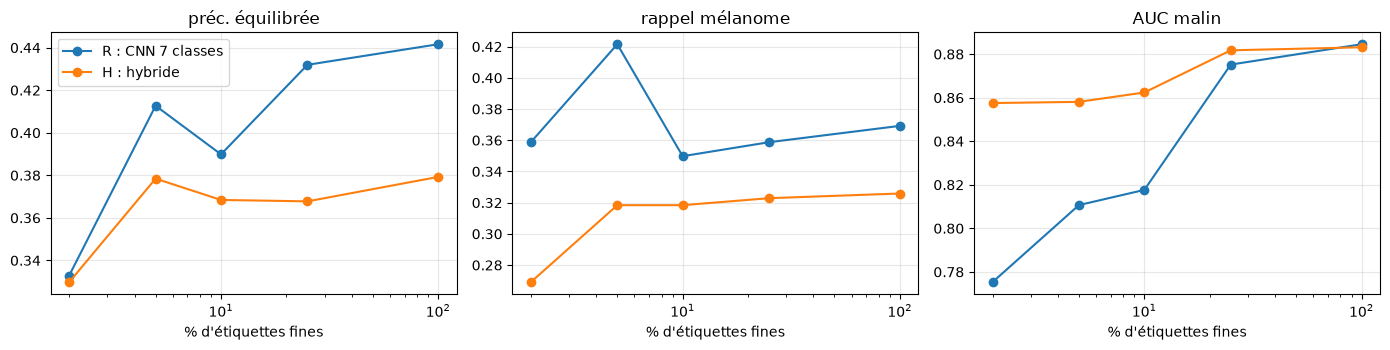

    2 % | préc. équilibrée R = 0.333  H = 0.330 | rappel mélanome R = 0.359  H = 0.269
    5 % | préc. équilibrée R = 0.413  H = 0.378 | rappel mélanome R = 0.422  H = 0.318
   10 % | préc. équilibrée R = 0.390  H = 0.368 | rappel mélanome R = 0.350  H = 0.318
   25 % | préc. équilibrée R = 0.432  H = 0.368 | rappel mélanome R = 0.359  H = 0.323
  100 % | préc. équilibrée R = 0.442  H = 0.379 | rappel mélanome R = 0.369  H = 0.326


In [12]:
FRACTIONS = [0.02, 0.05, 0.10, 0.25, 1.0]
courbe = {"R": [], "H": []}
for f in FRACTIONS:
    nom_reg = {1.0: "100 %", 0.10: "10 %"}.get(f, f"{int(f*100)} %")
    if nom_reg not in REGIMES: REGIMES[nom_reg] = masque_etiquettes(f)
    gr = GRAINES if nom_reg in ("100 %", "10 %") else [0]
    for court, nom in [("R", PRINCIPAUX[0]), ("H", PRINCIPAUX[2])]:
        lancer(nom_reg, nom, gr)
        courbe[court].append(resume(nom_reg, nom, graines=gr))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, met in zip(axes, ["préc. équilibrée", "rappel mélanome", "AUC malin"]):
    for court, lab in [("R", "R : CNN 7 classes"), ("H", "H : hybride")]:
        ax.plot([100 * f for f in FRACTIONS], [r[met][0] for r in courbe[court]], "o-", label=lab)
    ax.set_xscale("log"); ax.set_xlabel("% d'étiquettes fines"); ax.set_title(met); ax.grid(alpha=.3)
axes[0].legend(); plt.tight_layout(); plt.show()
for i, f in enumerate(FRACTIONS):
    print(f"{100*f:5.0f} % | préc. équilibrée R = {courbe['R'][i]['préc. équilibrée'][0]:.3f}  H = {courbe['H'][i]['préc. équilibrée'][0]:.3f}"
          f" | rappel mélanome R = {courbe['R'][i]['rappel mélanome'][0]:.3f}  H = {courbe['H'][i]['rappel mélanome'][0]:.3f}")

**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

(Une seule graine à 2 %, 5 % et 25 % : les points intermédiaires sont plus bruités.)

* **AUC malin** (graphique de droite) : c'est le résultat le plus net du projet. H garde une AUC d'environ **0,86 même
  avec 2 % des étiquettes fines**, alors que R tombe à environ **0,78**. La détection des malins de H dépend du groupe,
  connu partout, et presque pas des étiquettes fines. Les deux courbes se rejoignent à partir de 25 %.
* **Précision équilibrée et rappel du mélanome** : R est au-dessus de H à toutes les fractions, sauf à 2 % où la
  précision équilibrée est presque la même (0,333 contre 0,330). L'écart se réduit quand les étiquettes deviennent rares,
  ce qui va dans le sens de l'idée « la connaissance compte surtout quand les données manquent », mais H ne dépasse jamais
  R sur les types fins dans notre expérience.

Conclusion clinique : si l'objectif est de **trier bénin / malin** avec peu d'annotations fines, le modèle à deux têtes
avec la hiérarchie est clairement préférable ; s'il faut le **type exact**, la référence reste meilleure ici.

## 7. Calibration

Un modèle bien calibré qui annonce 80 % de confiance a raison 8 fois sur 10. C'est indispensable pour exploiter
l'incertitude (partie 10). On trace le **diagramme de fiabilité** et on teste la **mise à l'échelle par température**
(Guo et al., 2017) : on divise les logits par une température $T$ apprise sur la **validation**, ce qui ne change
pas les prédictions mais ajuste la confiance.

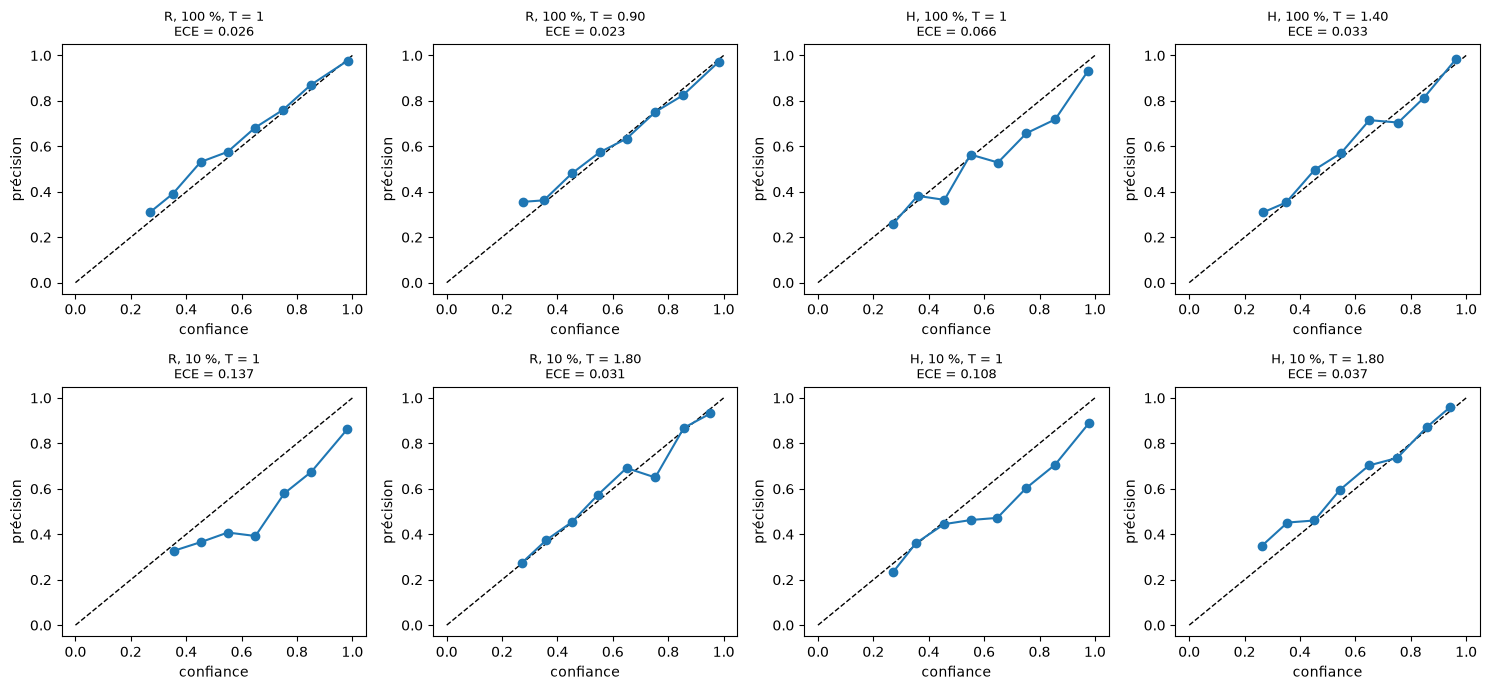

R  100 % : T = 0.90 | ECE avant 0.026 -> après 0.023
H  100 % : T = 1.40 | ECE avant 0.066 -> après 0.033
R   10 % : T = 1.80 | ECE avant 0.137 -> après 0.031
H   10 % : T = 1.80 | ECE avant 0.108 -> après 0.037


In [13]:
def fiabilite(ax, conf, correct, titre, n=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    bornes = np.linspace(0, 1, n + 1); xs, ys = [], []
    for a, b in zip(bornes[:-1], bornes[1:]):
        m = (conf > a) & (conf <= b)
        if m.sum() > 5: xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(xs, ys, "o-")
    ax.set_title(f"{titre}\nECE = {ece(conf, correct):.3f}", fontsize=9); ax.set_xlabel("confiance"); ax.set_ylabel("précision")

def temperature(net, mode):
    """Cherche T sur la validation (grille) en minimisant la log-vraisemblance négative du type décodé."""
    meilleur = (1e9, 1.0)
    for T in np.linspace(0.5, 3.0, 26):
        p, q = predire(net, Xva_n, T)
        _, _, dist, _ = decoder(p, q, mode)
        nll = -torch.log(dist[torch.arange(len(yva)), yva] + 1e-8).mean().item()
        meilleur = min(meilleur, (nll, T))
    return meilleur[1]

CALIB = {}
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for i, regime in enumerate(["100 %", "10 %"]):
    for j, (nom, lab) in enumerate([(PRINCIPAUX[0], "R"), (PRINCIPAUX[2], "H")]):
        net = MODELES[(regime, nom, 0)]
        p, q = SORTIES[(regime, nom, 0)]
        t, _, dist, _ = decoder(p, q)
        fiabilite(axes[i, 2 * j], dist.max(1).values, t == yte, f"{lab}, {regime}, T = 1")
        T = temperature(net, "coherent")
        p2, q2 = predire(net, Xte_n, T)
        t2, _, dist2, _ = decoder(p2, q2)
        fiabilite(axes[i, 2 * j + 1], dist2.max(1).values, t2 == yte, f"{lab}, {regime}, T = {T:.2f}")
        CALIB[(regime, lab)] = (T, ece(dist.max(1).values, t == yte), ece(dist2.max(1).values, t2 == yte))
plt.tight_layout(); plt.show()
for k, (T, e1, e2) in CALIB.items():
    print(f"{k[1]} {k[0]:>6s} : T = {T:.2f} | ECE avant {e1:.3f} -> après {e2:.3f}")

**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* Une température $T > 1$ signifie que le modèle est **trop sûr de lui**. C'est le cas de tous les modèles à 10 %
  ($T = 1{,}8$) et de H à 100 % ($T = 1{,}4$, à cause du décodage cohérent, voir partie 4).
* La température est très efficace : ECE de R à 10 % de **0,137 à 0,031**, de H à 10 % de **0,108 à 0,037**, de H à 100 %
  de 0,066 à 0,033. Elle ne change pas les prédictions, seulement la confiance.
* Après température, tous les modèles sont bien calibrés (ECE ≈ 0,02 à 0,04) : la calibration n'est donc pas un
  avantage décisif de l'hybride, mais une étape **indispensable** avant d'utiliser les probabilités (partie 10).
  C'est pourquoi la prédiction conforme utilise les températures apprises ici.

## 8. Cas difficiles

### 8.1 Classes rares et matrice de confusion

Le rappel par classe montre où se trouvent les difficultés : classes rares (dermatofibrome, lésions vasculaires)
et confusions entre lésions pigmentées (mélanome, nævus, kératose bénigne).

,R 100 %,H 100 %,R 10 %,H 10 %
akiec (228 ex.),0.354,0.313,0.313,0.303
bcc (359 ex.),0.579,0.460,0.460,0.476
bkl (769 ex.),0.432,0.402,0.398,0.417
df (80 ex.),0.000,0.000,0.072,0.000
mel (779 ex.),0.369,0.326,0.350,0.318
nv (4693 ex.),0.932,0.948,0.883,0.916
vasc (99 ex.),0.425,0.207,0.253,0.149


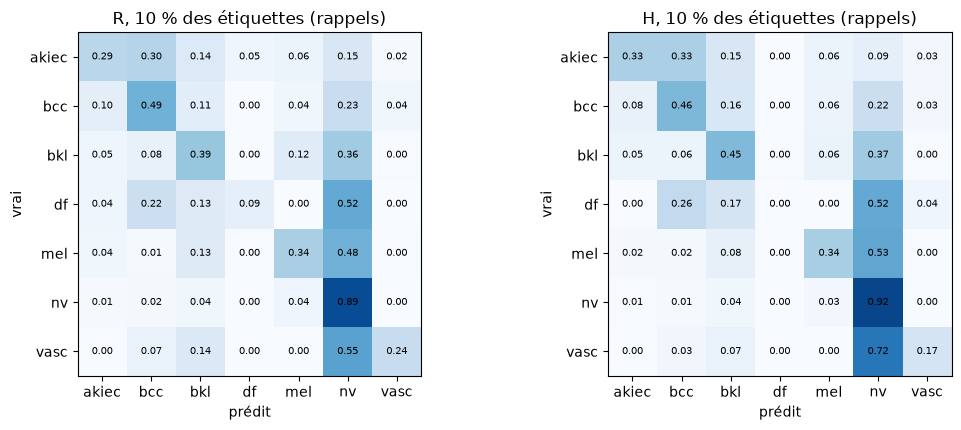

In [14]:
def rappels_par_classe(regime, nom):
    out = []
    for s in GRAINES:
        p, q = SORTIES[(regime, nom, s)]; t = decoder(p, q)[0]
        out.append([(t[yte == k] == k).float().mean().item() for k in range(7)])
    return np.mean(out, 0)

import pandas as pd
tab = pd.DataFrame({f"{lab} {reg}": rappels_par_classe(reg, nom) for reg in ["100 %", "10 %"]
                    for nom, lab in [(PRINCIPAUX[0], "R"), (PRINCIPAUX[2], "H")]},
                   index=[f"{ABREV[k]} ({(ytr == k).sum().item()} ex.)" for k in range(7)]).round(3)
display(tab)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (nom, lab) in zip(axes, [(PRINCIPAUX[0], "R"), (PRINCIPAUX[2], "H")]):
    p, q = SORTIES[("10 %", nom, 0)]
    cm = confusion_matrix(yte, decoder(p, q)[0], labels=range(7), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for a in range(7):
        for b in range(7): ax.text(b, a, f"{cm[a, b]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(7)); ax.set_xticklabels(ABREV); ax.set_yticks(range(7)); ax.set_yticklabels(ABREV)
    ax.set_xlabel("prédit"); ax.set_ylabel("vrai"); ax.set_title(f"{lab}, 10 % des étiquettes (rappels)")
plt.tight_layout(); plt.show()

**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* **Le dermatofibrome (df) n'est presque jamais reconnu** (80 images d'entraînement, 8 à 10 %), ni par R ni par H.
  Les lésions vasculaires (vasc) sont reconnues à 43 % par R à 100 %, mais beaucoup moins par H (21 %).
* La confusion dominante est **mélanome → nævus** (environ la moitié des mélanomes de test : 119 sur 223 pour H à 10 %) :
  à 28×28 pixels, ces deux lésions pigmentées se ressemblent beaucoup. Les kératoses bénignes sont aussi souvent prises
  pour des nævus.
* À 10 %, H est meilleur que R sur bcc (0,476 contre 0,460), bkl et nv, mais moins bon sur les bénins rares (vasc, df),
  comme expliqué en partie 5 : la règle pousse vers la classe dominante du groupe.
* La précision globale (~0,71 à 0,76) est trompeuse : elle est portée par nv. D'où la précision équilibrée et le rappel
  par classe.

### 8.2 Cas où la règle s'applique : les deux têtes se contredisent

On isole les images de test où, **avant décodage**, la tête type et la tête groupe du modèle M (sans règle)
se contredisent. C'est exactement là que la connaissance symbolique a quelque chose à dire. On compare sur
ces images : M en décodage brut, M en décodage cohérent et H.

In [15]:
for regime in ["100 %", "10 %"]:
    pM, qM = SORTIES[(regime, PRINCIPAUX[1], 0)]
    conflit = GROUPE[pM.argmax(1)] != qM.argmax(1)
    pH, qH = SORTIES[(regime, PRINCIPAUX[2], 0)]
    conflit_H = GROUPE[pH.argmax(1)] != qH.argmax(1)
    print(f"Régime {regime} : {int(conflit.sum())} images en conflit pour M ({conflit.float().mean():.1%}),"
          f" {int(conflit_H.sum())} pour H avant décodage ({conflit_H.float().mean():.1%})")
    for lab, (p, q), mode in [("M brut, type", (pM, qM), "brut"), ("M cohérent", (pM, qM), "coherent"),
                              ("H cohérent", (pH, qH), "coherent")]:
        t, g, _, _ = decoder(p, q, mode)
        print(f"   sur les images en conflit de M | {lab:13s}: type juste {(t[conflit] == yte[conflit]).float().mean():.3f}"
              f" | groupe juste {(g[conflit] == gte[conflit]).float().mean():.3f}")
    # sur les conflits de M, la tête groupe seule fait-elle mieux que le type seul ?
    print(f"   sur ces images, groupe juste selon la tête groupe de M : {(qM.argmax(1)[conflit] == gte[conflit]).float().mean():.3f}"
          f" ; selon la tête type de M : {(GROUPE[pM.argmax(1)][conflit] == gte[conflit]).float().mean():.3f}")

Régime 100 % : 98 images en conflit pour M (4.9%), 57 pour H avant décodage (2.8%)
   sur les images en conflit de M | M brut, type : type juste 0.439 | groupe juste 0.510
   sur les images en conflit de M | M cohérent   : type juste 0.429 | groupe juste 0.602
   sur les images en conflit de M | H cohérent   : type juste 0.408 | groupe juste 0.571
   sur ces images, groupe juste selon la tête groupe de M : 0.510 ; selon la tête type de M : 0.490
Régime 10 % : 100 images en conflit pour M (5.0%), 57 pour H avant décodage (2.8%)
   sur les images en conflit de M | M brut, type : type juste 0.380 | groupe juste 0.510
   sur les images en conflit de M | M cohérent   : type juste 0.290 | groupe juste 0.470
   sur les images en conflit de M | H cohérent   : type juste 0.380 | groupe juste 0.600
   sur ces images, groupe juste selon la tête groupe de M : 0.510 ; selon la tête type de M : 0.490


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* Quand les deux têtes de M se contredisent, aucune n'est fiable : la tête groupe a raison sur le groupe 51 % du temps,
  la tête type 49 %, soit **pile ou face**. Ce sont des images réellement ambiguës, qu'il faut signaler plutôt
  que trancher (partie 10).
* **À 10 %, sur ces images, H fait mieux** : groupe juste à **60 %** contre 51 % pour M brut (type juste : 38 % pour les
  deux). C'est le cas où la règle s'applique, et la contrainte apprise à l'entraînement y apporte quelque chose.
* À 100 %, c'est M avec le seul décodage cohérent qui trouve le mieux le groupe (60 %, contre 57 % pour H) : quand les
  étiquettes fines sont toutes là, la brique symbolique de sortie suffit.
* H a presque deux fois moins de conflits avant décodage que M : 2,8 % contre 5,0 % à 10 %.

### 8.3 Robustesse : images perturbées

On applique au test des perturbations qui imitent des conditions d'acquisition différentes : bruit, sous-exposition,
flou, contraste réduit. On regarde la précision équilibrée, le rappel du mélanome et la **confiance moyenne** :
un modèle robuste ne devrait pas rester très sûr de lui quand ses prédictions se dégradent.

In [16]:
fixer_graine(0)
PERTURB = {
    "aucune": lambda X: X,
    "bruit σ=0,08": lambda X: (X + 0.08 * torch.randn_like(X)).clamp(0, 1),
    "sous-exposition ×0,6": lambda X: X * 0.6,
    "flou 3×3": lambda X: F.avg_pool2d(F.pad(X, (1, 1, 1, 1), mode="replicate"), 3, 1),
    "contraste ×0,5": lambda X: (X - X.mean((2, 3), keepdim=True)) * 0.5 + X.mean((2, 3), keepdim=True),
}
lignes = []
for nom_p, f in PERTURB.items():
    Xp = normaliser(f(Xte))
    for regime in ["100 %", "10 %"]:
        for nom, lab in [(PRINCIPAUX[0], "R"), (PRINCIPAUX[2], "H")]:
            p, q = predire(MODELES[(regime, nom, 0)], Xp)
            r = evaluer(p, q, yte); conf = decoder(p, q)[2].max(1).values.mean().item()
            lignes.append({"perturbation": nom_p, "modèle": f"{lab} {regime}", "préc. équilibrée": r["préc. équilibrée"],
                           "rappel mélanome": r["rappel mélanome"], "AUC malin": r["AUC malin"], "confiance moy.": conf})
ROB = pd.DataFrame(lignes)
display(ROB.pivot(index="perturbation", columns="modèle", values="préc. équilibrée").round(3))
display(ROB.pivot(index="perturbation", columns="modèle", values="AUC malin").round(3))

modèle,H 10 %,H 100 %,R 10 %,R 100 %
perturbation,,,,
aucune,0.381,0.374,0.388,0.441
"bruit σ=0,08",0.192,0.247,0.208,0.284
"contraste ×0,5",0.253,0.274,0.294,0.297
flou 3×3,0.271,0.261,0.314,0.346
"sous-exposition ×0,6",0.169,0.150,0.138,0.153


modèle,H 10 %,H 100 %,R 10 %,R 100 %
perturbation,,,,
aucune,0.866,0.879,0.808,0.887
"bruit σ=0,08",0.387,0.594,0.423,0.655
"contraste ×0,5",0.821,0.827,0.745,0.833
flou 3×3,0.854,0.858,0.798,0.877
"sous-exposition ×0,6",0.664,0.713,0.416,0.626


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

(Graine 0 ; première table : précision équilibrée, seconde : AUC malin.)

* Tous les modèles se dégradent fortement. La **sous-exposition** est la pire pour les types fins (précision équilibrée
  ≈ 0,14 à 0,17, le modèle répond presque toujours « nævus ») ; le **bruit** fait aussi chuter l'AUC malin vers 0,39 à 0,66.
* Sur la **détection des malins**, H résiste mieux que R : AUC sous sous-exposition **0,664 contre 0,416** à 10 %,
  0,713 contre 0,626 à 100 % ; sous contraste réduit 0,821 contre 0,745 à 10 %. La tête groupe, entraînée sur toutes
  les images, généralise mieux.
* Sur les types fins, R reste un peu meilleur, comme sans perturbation.
* Un déploiement réel demanderait une **règle de contrôle qualité en entrée** (exposition, netteté) et de l'augmentation
  de données photométrique ; la hiérarchie seule ne protège pas contre ces changements.

### 8.4 Hors distribution

On présente au modèle des images qui ne sont **pas** des lésions de peau : des chiffres manuscrits MNIST
(mis en couleur) et du bruit uniforme. Un modèle sain devrait être **peu confiant**. On compare la confiance maximale
sur ces images à celle sur le vrai test, et l'on mesure l'AUROC de détection « dans / hors distribution » obtenue en
utilisant simplement la confiance comme score (Hendrycks et Gimpel, 2017).

In [17]:
def images_hors_distribution(n=1000):
    sorties = {}
    try:
        import torchvision
        m = torchvision.datasets.MNIST("data", train=False, download=True)
        X = m.data[:n].float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
        sorties["MNIST (chiffres)"] = X
    except Exception as e:
        print("MNIST indisponible :", type(e).__name__)
    g = torch.Generator().manual_seed(0)
    sorties["bruit uniforme"] = torch.rand(n, 3, 28, 28, generator=g)
    return sorties

OOD = images_hors_distribution()
for regime in ["100 %", "10 %"]:
    for nom, lab in [(PRINCIPAUX[0], "R"), (PRINCIPAUX[2], "H")]:
        net = MODELES[(regime, nom, 0)]
        c_in = decoder(*predire(net, Xte_n))[2].max(1).values
        txt = f"{lab} {regime:>6s} | confiance test = {c_in.mean():.3f}"
        for nom_o, Xo in OOD.items():
            c_out = decoder(*predire(net, normaliser(Xo)))[2].max(1).values
            auroc = roc_auc_score(np.r_[np.ones(len(c_in)), np.zeros(len(c_out))], np.r_[c_in, c_out])
            pm = decoder(*predire(net, normaliser(Xo)))[3]
            txt += f" | {nom_o} : confiance {c_out.mean():.3f}, AUROC {auroc:.3f}, % jugés malins {(pm > .5).float().mean():.0%}"
        print(txt)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.48MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 334kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.88MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


R  100 % | confiance test = 0.746 | MNIST (chiffres) : confiance 0.989, AUROC 0.195, % jugés malins 100% | bruit uniforme : confiance 0.716, AUROC 0.574, % jugés malins 11%
H  100 % | confiance test = 0.808 | MNIST (chiffres) : confiance 1.000, AUROC 0.001, % jugés malins 100% | bruit uniforme : confiance 0.973, AUROC 0.330, % jugés malins 100%
R   10 % | confiance test = 0.851 | MNIST (chiffres) : confiance 1.000, AUROC 0.002, % jugés malins 100% | bruit uniforme : confiance 1.000, AUROC 0.003, % jugés malins 100%
H   10 % | confiance test = 0.838 | MNIST (chiffres) : confiance 0.999, AUROC 0.009, % jugés malins 100% | bruit uniforme : confiance 0.974, AUROC 0.291, % jugés malins 0%


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

C'est le résultat le plus inquiétant : face à des **chiffres manuscrits**, tous les modèles répondent avec une confiance
de **0,99 à 1,00**, plus élevée que sur les vraies lésions, et les classent tous comme **malins**. Une AUROC proche
de 0 signifie que les images hors distribution reçoivent une confiance *plus haute* que les vraies : la confiance ne permet
pas de les rejeter. Le bruit uniforme n'est détecté que partiellement par R à 100 % (AUROC 0,57).

La hiérarchie n'y peut rien : elle contraint le choix **entre les 7 types connus**, elle ne sait pas dire « aucun d'eux ».
La prédiction conforme non plus, puisque ses ensembles s'appuient sur les mêmes probabilités. Il faudrait une brique
dédiée : un détecteur hors distribution, ou une **règle symbolique en entrée** (une image dermatoscopique a des
statistiques de couleur et de texture précises ; un chiffre blanc sur fond noir ne les a pas).

## 9. Analyse d'erreurs brique par brique

Pour le modèle hybride (régime 10 %, graine 0), on attribue chaque erreur de type sur le test à la brique responsable :

* **Perception du groupe** : le groupe final est faux (le réseau s'est trompé de famille bénin / malin) ;
* **Perception intra-groupe** : le groupe est juste mais le type faux (par exemple nævus pris pour une kératose bénigne).
  La hiérarchie ne peut rien ici : la règle ne contraint que le groupe ;
* **Décodage symbolique** : la tête type seule avait raison, et c'est le décodage cohérent qui a changé la réponse.

On compte aussi l'inverse : les erreurs **corrigées** par le décodage (tête type seule fausse, réponse cohérente juste).

In [18]:
def analyse_erreurs(regime, nom, s=0):
    p, q = SORTIES[(regime, nom, s)]
    t_brut = p.argmax(1)
    t, g, _, _ = decoder(p, q)
    err = t != yte
    dec_resp = err & (t_brut == yte)               # catégories exclusives, dans cet ordre
    cat = {
        "décodage symbolique (tête type avait raison)": dec_resp,
        "perception du groupe": err & ~dec_resp & (g != gte),
        "perception intra-groupe": err & ~dec_resp & (g == gte),
    }
    print(f"{nom}, régime {regime} : {int(err.sum())} erreurs sur {len(yte)} ({err.float().mean():.1%})")
    for k, m in cat.items():
        print(f"   {k:46s}: {int(m.sum()):4d} ({m.sum() / max(1, err.sum()):.0%} des erreurs)")
    corr = (t_brut != yte) & (t == yte)
    print(f"   erreurs de la tête type CORRIGÉES par le décodage : {int(corr.sum())}")
    # erreurs de groupe : dans quel sens ?
    fn = ((g == 0) & (gte == 1)).sum().item(); fp = ((g == 1) & (gte == 0)).sum().item()
    print(f"   erreurs de groupe : {fn} malins classés bénins (dangereux), {fp} bénins classés malins")
    # confusions les plus fréquentes
    paires = {}
    for a, b in zip(yte[err].tolist(), t[err].tolist()):
        paires[(a, b)] = paires.get((a, b), 0) + 1
    top = sorted(paires.items(), key=lambda x: -x[1])[:5]
    print("   confusions les plus fréquentes :", ", ".join(f"{ABREV[a]}→{ABREV[b]} ({n})" for (a, b), n in top))
    return cat

_ = analyse_erreurs("10 %", PRINCIPAUX[2])
print()
_ = analyse_erreurs("10 %", PRINCIPAUX[1])
print()
_ = analyse_erreurs("100 %", PRINCIPAUX[2])

H : hybride (règle + cohérence), régime 10 % : 527 erreurs sur 2005 (26.3%)
   décodage symbolique (tête type avait raison)  :    8 (2% des erreurs)
   perception du groupe                          :  295 (56% des erreurs)
   perception intra-groupe                       :  224 (43% des erreurs)
   erreurs de la tête type CORRIGÉES par le décodage : 8
   erreurs de groupe : 197 malins classés bénins (dangereux), 106 bénins classés malins
   confusions les plus fréquentes : mel→nv (119), bkl→nv (81), nv→bkl (50), nv→mel (38), bcc→nv (23)

M : multi-tâche sans règle, régime 10 % : 554 erreurs sur 2005 (27.6%)
   décodage symbolique (tête type avait raison)  :   14 (3% des erreurs)
   perception du groupe                          :  309 (56% des erreurs)
   perception intra-groupe                       :  231 (42% des erreurs)
   erreurs de la tête type CORRIGÉES par le décodage : 5
   erreurs de groupe : 191 malins classés bénins (dangereux), 132 bénins classés malins
   confusions les p

**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* **Perception du groupe : 56 % des erreurs.** Le réseau se trompe de famille. Le cas le plus fréquent et le plus
  dangereux est **mélanome → nævus** (119 images pour H à 10 %) ; au total, 197 malins sont classés bénins.
* **Perception intra-groupe : 42 à 43 %.** Le groupe est juste mais le type faux (kératose bénigne ↔ nævus surtout).
  La hiérarchie ne peut pas corriger ces erreurs, par définition.
* **Décodage symbolique : 2 à 3 %.** Pour H à 10 %, le décodage cohérent introduit 8 erreurs et en corrige 8 : son
  effet net sur la précision est nul (pour M : 14 introduites, 5 corrigées), et il garantit des sorties cohérentes.

**Bilan : le goulot d'étranglement est la perception**, pas la logique : 98 % des erreurs de H à 10 % viennent du
réseau. Le CNN ne distingue pas assez bien les lésions pigmentées à 28×28. La brique symbolique fait peu d'erreurs, et
chacune est **traçable** (on sait quelle règle a changé la réponse), ce qui n'est pas le cas des erreurs du réseau.

## 10. Explication d'une décision et règle d'escalade

### 10.1 Prédiction conforme

Plutôt qu'un seul diagnostic, on renvoie un **ensemble** de types qui contient le vrai type avec une probabilité
garantie d'au moins $1 - \alpha$ (ici 90 %), sous la seule hypothèse que test et calibration sont échangeables
(prédiction conforme « split », Angelopoulos et Bates, 2021).

1. Sur la validation, score de non-conformité $s_i = 1 - \hat p(y_i \mid x_i)$ ;
2. seuil $\hat\tau$ = quantile $\lceil (n+1)(1-\alpha) \rceil / n$ des scores ;
3. pour une nouvelle image, ensemble = tous les types $k$ avec $1 - \hat p(k \mid x) \le \hat\tau$.

**Règle d'escalade** (brique symbolique) : on transmet au dermatologue si l'ensemble contient au moins un type
malin / pré-malin **et** plus d'un type, c'est-à-dire si le modèle ne peut pas exclure un cancer sans hésiter.
Si l'ensemble ne contient que des types malins, c'est une alerte directe ; s'il ne contient que des bénins, pas d'alerte.

In [19]:
ALPHA = 0.10
def conforme(net, alpha=ALPHA, T=1.0):
    pv, qv = predire(net, Xva_n, T); dv = decoder(pv, qv)[2]
    scores = 1 - dv[torch.arange(len(yva)), yva]
    n = len(scores); niveau = min(1, np.ceil((n + 1) * (1 - alpha)) / n)
    tau = torch.quantile(scores, niveau).item()
    pt, qt = predire(net, Xte_n, T); dt = decoder(pt, qt)[2]
    ens = (1 - dt) <= tau                                     # (N, 7) ensembles de prédiction
    return ens, dt, tau

def decision(ens):
    mal = ens[:, GROUPE == 1].any(1); ben = ens[:, GROUPE == 0].any(1)
    return np.where(mal & ben, "escalade dermatologue", np.where(mal, "alerte : malin probable", "bénin, pas d'alerte"))

for regime in ["100 %", "10 %"]:
    for nom, lab in [(PRINCIPAUX[0], "R"), (PRINCIPAUX[2], "H")]:
        net = MODELES[(regime, nom, 0)]
        T = CALIB[(regime, lab)][0]
        ens, dt, tau = conforme(net, T=T)
        couv = ens[torch.arange(len(yte)), yte].float().mean().item()
        dec = decision(ens)
        mal = (gte == 1).numpy()
        rate = mal & (dec == "bénin, pas d'alerte")
        print(f"{lab} {regime:>6s} | couverture {couv:.3f} (visée {1-ALPHA:.2f}) | taille moyenne {ens.sum(1).float().mean():.2f}"
              f" | escalade {np.mean(dec == 'escalade dermatologue'):.1%} | alerte directe {np.mean(dec == 'alerte : malin probable'):.1%}"
              f" | malins passés sans alerte : {rate.sum()}/{mal.sum()} ({rate.sum()/mal.sum():.1%})")

R  100 % | couverture 0.907 (visée 0.90) | taille moyenne 1.60 | escalade 32.8% | alerte directe 3.1% | malins passés sans alerte : 67/392 (17.1%)
H  100 % | couverture 0.895 (visée 0.90) | taille moyenne 1.76 | escalade 18.2% | alerte directe 6.7% | malins passés sans alerte : 126/392 (32.1%)
R   10 % | couverture 0.897 (visée 0.90) | taille moyenne 1.94 | escalade 44.2% | alerte directe 2.1% | malins passés sans alerte : 71/392 (18.1%)
H   10 % | couverture 0.908 (visée 0.90) | taille moyenne 2.08 | escalade 24.8% | alerte directe 5.4% | malins passés sans alerte : 104/392 (26.5%)


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* **La garantie de couverture tient** : 0,895 à 0,908 pour 0,90 visé, pour tous les modèles. C'est l'intérêt de la
  prédiction conforme : une garantie qui ne dépend pas de la qualité du réseau.
* **Compromis entre escalade et sécurité.** H escalade presque deux fois moins (24,8 % des images contre 44,2 % pour R
  à 10 %), donc moins de fatigue d'alerte, mais laisse passer **plus de malins sans alerte** (26,5 % contre 18,1 %). Les
  ensembles de R mélangent plus souvent bénins et malins, ce qui déclenche plus d'escalades et rate moins de cancers.
* Cliniquement, rater un mélanome est bien plus grave qu'une consultation de trop : il faudrait choisir un $\alpha$ plus
  petit (ensembles plus grands) ou une règle d'escalade plus prudente (par exemple escalader dès que la probabilité malin
  dépasse un seuil bas).
* Aucun de ces modèles n'est utilisable tel quel : 17 à 32 % de malins sans alerte, c'est beaucoup trop pour du dépistage.

### 10.2 Explication pour une image

Pour chaque image, on présente ensemble : les probabilités des types, la probabilité du groupe, la règle utilisée
(type ⇒ groupe), l'ensemble conforme et la décision. Tout est **vérifiable** par un médecin : chaque étape cite la règle.

--- mélanome bien reconnu ---
Image test n°15 — vrai type : mel (mélanome), groupe malin/pré-malin
  Tête type   : mel 0.49, nv 0.38, bkl 0.05
  Tête groupe : malin 0.52
  Décodage cohérent : mel 0.51, nv 0.37, bkl 0.04
  Règle : type = mel ⇒ groupe = malin/pré-malin (hiérarchie HAM10000)
  Ensemble conforme 90 % : {mel, nv}
  Décision : escalade dermatologue

--- mélanome manqué par le type ---
Image test n°2 — vrai type : mel (mélanome), groupe malin/pré-malin
  Tête type   : bkl 0.48, nv 0.26, mel 0.09
  Tête groupe : malin 0.19
  Décodage cohérent : bkl 0.56, nv 0.30, df 0.06
  Règle : type = bkl ⇒ groupe = bénin (hiérarchie HAM10000)
  Ensemble conforme 90 % : {bkl, nv}
  Décision : bénin, pas d'alerte

--- nævus évident ---
Image test n°11 — vrai type : nv (nævus), groupe bénin
  Tête type   : nv 0.97, bkl 0.01, df 0.01
  Tête groupe : malin 0.00
  Décodage cohérent : nv 0.98, bkl 0.01, df 0.01
  Règle : type = nv ⇒ groupe = bénin (hiérarchie HAM10000)
  Ensemble conforme 90 % : 

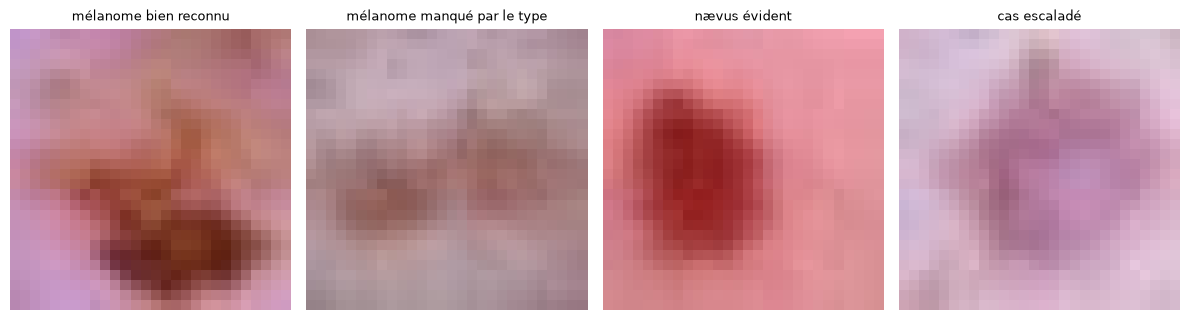

In [20]:
net = MODELES[("10 %", PRINCIPAUX[2], 0)]
T = CALIB[("10 %", "H")][0]
ens, dt, tau = conforme(net, T=T)
p, q = predire(net, Xte_n, T)
dec = decision(ens)

def expliquer(i):
    t = dt[i].argmax().item()
    top = dt[i].argsort(descending=True)[:3]
    lignes = [f"Image test n°{i} — vrai type : {ABREV[yte[i]]} ({NOMS_FR[yte[i]]}), groupe {NOMS_GROUPE[gte[i]]}",
              "  Tête type   : " + ", ".join(f"{ABREV[k]} {p[i, k]:.2f}" for k in p[i].argsort(descending=True)[:3]),
              f"  Tête groupe : malin {q[i, 1]:.2f}",
              "  Décodage cohérent : " + ", ".join(f"{ABREV[k]} {dt[i, k]:.2f}" for k in top),
              f"  Règle : type = {ABREV[t]} ⇒ groupe = {NOMS_GROUPE[GROUPE[t]]} (hiérarchie HAM10000)",
              f"  Ensemble conforme 90 % : {{{', '.join(ABREV[k] for k in range(7) if ens[i, k])}}}",
              f"  Décision : {dec[i]}"]
    return "\n".join(lignes)

# quatre cas : un mélanome détecté, un mélanome difficile, un nævus évident, un cas escaladé
cands = {
    "mélanome bien reconnu": ((yte == MEL) & (dt.argmax(1) == MEL)).nonzero().view(-1),
    "mélanome manqué par le type": ((yte == MEL) & (dt.argmax(1) != MEL)).nonzero().view(-1),
    "nævus évident": ((yte == 5) & (dt.max(1).values > 0.95)).nonzero().view(-1),
    "cas escaladé": torch.tensor(np.where(dec == "escalade dermatologue")[0]),
}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (titre, idx) in zip(axes, cands.items()):
    if len(idx) == 0: ax.axis("off"); continue
    i = idx[0].item()
    ax.imshow(Xte[i].permute(1, 2, 0)); ax.axis("off"); ax.set_title(titre, fontsize=9)
    print(f"--- {titre} ---\n{expliquer(i)}\n")
plt.tight_layout(); plt.show()

**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

* L'explication enchaîne **mesures → règle → ensemble → décision**, chaque étape étant vérifiable par un médecin.
* Le **mélanome manqué** est instructif : le réseau voit une kératose bénigne (0,48) et un nævus, la tête groupe ne donne
  que 0,19 de malin, et l'ensemble conforme {bkl, nv} exclut le mélanome. L'erreur vient de la **perception** (partie 9) ;
  l'explication montre exactement où.
* Le **mélanome bien reconnu** est quand même escaladé, car le nævus reste dans l'ensemble : c'est le comportement voulu,
  le modèle n'exclut pas l'hypothèse bénigne mais ne laisse pas passer l'hypothèse maligne.
* Le **cas escaladé** (un dermatofibrome, classe rare) montre un modèle qui hésite entre 4 types de deux groupes : la tête
  type penche pour un carcinome basocellulaire, le décodage cohérent pour une lésion vasculaire. L'escalade est la bonne
  décision.

## 11. Coût et synthèse

### 11.1 Coût

In [21]:
for nom in PRINCIPAUX:
    temps = [MODELES[("10 %", nom, s)].temps for s in GRAINES]
    n_par = sum(p.numel() for p in MODELES[("10 %", nom, 0)].parameters())
    print(f"{nom:36s} | {n_par} paramètres | entraînement {np.mean(temps):.0f} s ({PAS} pas, {DEVICE})")
net = MODELES[("10 %", PRINCIPAUX[2], 0)]
t0 = time.time(); _ = predire(net, Xte_n); dt_inf = time.time() - t0
print(f"Inférence + décodage cohérent sur {len(yte)} images : {dt_inf:.2f} s ({1000*dt_inf/len(yte):.2f} ms par image)")

R : CNN 7 classes (référence)        | 33575 paramètres | entraînement 47 s (1200 pas, cpu)
M : multi-tâche sans règle           | 33705 paramètres | entraînement 41 s (1200 pas, cpu)
H : hybride (règle + cohérence)      | 33705 paramètres | entraînement 42 s (1200 pas, cpu)
Inférence + décodage cohérent sur 2005 images : 0.17 s (0.08 ms par image)


**Lecture des résultats** (valeurs de notre exécution ; une réexécution donne des valeurs proches, pas identiques).

Le coût de l'hybride est négligeable : 130 paramètres de plus (la tête groupe), un temps d'entraînement identique
(≈ 40 à 50 s pour 1200 pas sur CPU) et un décodage cohérent qui ne coûte qu'un produit de 7 nombres par image.
Le vrai coût est ailleurs : **l'expertise** pour écrire et sourcer la hiérarchie, et les étiquettes de groupe, moins chères
que les étiquettes fines mais pas gratuites (une biopsie tranche entre bénin et malin).

### 11.2 Synthèse sur la grille d'évaluation

Comparaison dans le régime **10 % d'étiquettes fines** (le cas qui motive le sujet), R contre H.

| Dimension | R : CNN 7 classes | H : hybride | Verdict |
|---|---|---|---|
| **Performance (types fins)** | préc. équilibrée 0,390, rappel mélanome 0,350 | 0,368, 0,318 | R un peu meilleur |
| **Performance (bénin / malin)** | AUC malin 0,818 (≈ 0,78 à 2 %) | **0,862** (≈ 0,86 à 2 %) | **H nettement meilleur**, surtout avec très peu d'étiquettes |
| **Cohérence** | cohérent par construction (une seule tête) | 3,8 % de conflits entre têtes avant décodage (5,7 % sans règle), **0 %** après | H : deux avis indépendants, toujours réconciliés |
| **Calibration** | ECE ≈ 0,14 → 0,03 après température | ≈ 0,11 (0,073 en décodage brut) → 0,04 | équivalents après température |
| **Robustesse** | AUC malin 0,42 sous sous-exposition | 0,66 | H plus robuste pour bénin / malin ; tous deux fragiles et aveugles hors distribution |
| **Explicabilité** | type prédit et probabilités | type, groupe, règle déclenchée, ensemble conforme, décision | H plus riche (la règle est explicite et citée) |
| **Coût** | 33 575 paramètres, ≈ 45 s | 33 705 paramètres, ≈ 42 s | identique |

**Conclusion.**

1. La hiérarchie bénin / malin **aide nettement là où elle apporte de l'information** : la décision bénin / malin avec très
   peu d'étiquettes fines (AUC 0,86 contre 0,78 à 2 %), et la cohérence des sorties.
2. Elle **n'aide pas** à reconnaître le type exact : une règle « type ⇒ groupe » ne dit rien à l'intérieur d'un groupe
   et pousse vers la classe dominante. Comme la règle du maximum du TP, c'est une règle **peu informative** ; il faudrait
   une connaissance plus fine (par exemple des critères dermoscopiques type ABCD reliés aux types) pour aider les types.
3. L'ablation montre que l'essentiel du gain vient de **l'étiquette de groupe** (M fait presque aussi bien que H) ; la règle
   groupe ⇒ type ajoute un peu, la perte de cohérence rien de mesurable, et Łukasiewicz fait un peu mieux que la semantic loss.
4. Les limites principales sont **la perception** (mélanome ↔ nævus à 28×28) et **l'absence de détection hors
   distribution** ; ni l'une ni l'autre ne se corrige avec cette hiérarchie.

**Limites de l'étude.** Images 28×28 (l'objectif était l'apport de la contrainte, pas l'état de l'art) ; 3 graines
seulement, une seule pour les fractions intermédiaires et les parties 7 à 10 ; aucune pondération des classes ; une seule
population (HAM10000 : patients principalement d'Autriche et d'Australie, peaux claires) : les conclusions ne s'étendent pas
à d'autres phototypes sans vérification.

**Pistes.** Pondérer les classes ou rééchantillonner ; ajouter des critères dermoscopiques comme connaissance plus riche ;
une règle de contrôle qualité et un détecteur hors distribution en entrée ; formulation DeepProbLog du même modèle.

## Sources

**Données**
* Tschandl P., Rosendahl C., Kittler H. *The HAM10000 dataset, a large collection of multi-source dermatoscopic images of
  common pigmented skin lesions.* Scientific Data 5, 180161 (2018). doi:10.1038/sdata.2018.161. Source des images, des 7 catégories et de leur
  description (bénignes, malignes ou pré-malignes).
* Yang J. et al. *MedMNIST v2 – A large-scale lightweight benchmark for 2D and 3D biomedical image classification.*
  Scientific Data 10, 41 (2023). doi:10.1038/s41597-022-01721-8. DermaMNIST, découpage entraînement / validation / test.

**Connaissance médicale (hiérarchie)**
* Tschandl et al. (2018), ci-dessus : description des 7 catégories (bcc et mel malins, akiec pouvant évoluer en carcinome,
  nv, bkl et df bénins ; vasc non qualifié, classé bénin par nous).
* de Berker D. et al. *British Association of Dermatologists' guidelines for the care of patients with actinic keratosis
  2017.* British Journal of Dermatology 176(1), 20–43 (2017). doi:10.1111/bjd.15107. La kératose actinique comme lésion
  pré-maligne, à faible risque de progression (moins d'une sur 1 000 par an).

**Méthodes**
* Xu J., Zhang Z., Friedman T., Liang Y., Van den Broeck G. *A Semantic Loss Function for Deep Learning with Symbolic
  Knowledge.* ICML 2018.
* Badreddine S., d'Avila Garcez A., Serafini L., Spranger M. *Logic Tensor Networks.* Artificial Intelligence 303 (2022).
* Manhaeve R. et al. *DeepProbLog: Neural Probabilistic Logic Programming.* NeurIPS 2018.
* Guo C., Pleiss G., Sun Y., Weinberger K. *On Calibration of Modern Neural Networks.* ICML 2017.
* Hendrycks D., Gimpel K. *A Baseline for Detecting Misclassified and Out-of-Distribution Examples in Neural Networks.* ICLR 2017.
* Angelopoulos A., Bates S. *A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification.*
  arXiv:2107.07511 (2021).